# DATA722 Phase 2: AI use case registration and risk-tiering chatbot (use case C)

| | |
|---|---|
| Course | DATA722 Generative AI & Strategic Forecasting (Instructor: Danish Haroon) |
| Student | Azmina Lalani,  |
| Use case | C: a chatbot each team uses to register its AI use case. It checks the brief against the EU AI Act, NIST AI RMF and AIGP, asks follow-up questions about what is missing, and produces a risk tier assessment, the affected parties, a model card and a system card that are added to the AI inventory. |
| Hosted application | https://gen-ai-mid.vercel.app |
| Source code | https://github.com/lalaniazmina95-tech/GEN-AI-Mid |
| Model | OpenAI `gpt-oss-120b` (open-weight) served by Groq |
| Data | **Synthetic only.** All use cases, teams, vendors and inventory records are fictional (Phase 1, question 6: no customer data is needed or accepted). |

This notebook is the working record. It contains:

1. what was built and how it traces to the Phase 1 assessment;
2. the synthetic data and the framework knowledge base;
3. the prompts, context design and agent loop at the centre of the system;
4. a live registration traced turn by turn, with tokens and cost;
5. how I got there: the version 1 baseline, the development iterations and the failures found;
6. the evaluation: the Phase 1 metrics run against the built system, with scores, on a development set and a held-out set;
7. token and cost figures;
8. the honesty section.

**Phase 1 verdict and what I built.** Phase 1 rated use case C *Go, reduced scope*. I built it under that reduced scope and did not reverse any of the reductions: the chatbot only drafts; registrations stay pending until the AI governance office (or the committee for high-risk and above-appetite cases) approves them; hard minimum-tier rules cannot be lowered by the conversation; cards never fill gaps with assumptions; customer data is blocked before the model. The one thing Phase 1 named as the next increment, integration with the vendor and IT asset registers, is **not** built.

## 1. Traceability: Phase 1 commitments and where they are implemented

| Phase 1 commitment | Implemented in |
|---|---|
| Team self-service chatbot, follow-ups driven by EU AI Act, NIST AI RMF, AIGP | `engine/agent.py` (loop), `engine/kb/schema.py` (40-field question bank with clause mapping), `engine/gaps.py` |
| Asks only about what is missing (redundant-question rate <= 5%) | deterministic gap selection in `engine/gaps.py`; extraction keeps what was already said |
| Administrator sets the risk appetite and minimum-tier rules | `engine/config.py`, Admin tab, `PUT /api/config` |
| Output: risk tier assessment, affected parties, model card, system card | `Agent.finalize`, `engine/cards.py`; Register tab result view; Markdown/JSON download |
| Adds up into the inventory, pending approval | `engine/store.py`, Inventory tab, `POST /api/decision` (role-gated) |
| Hard rules set a minimum tier (credit decisions about individuals, biometric identification, acting on customers without review start at high) | `engine/rules.py` `floor_signals` |
| Cards never fill gaps with assumptions | `engine/cards.py` (`Not provided` + open items); quote verification in `engine/verify.py` |
| Personal-data check before the model; documents, not datasets | `engine/pii.py`; the UI accepts only `.txt` / `.md` |
| The chatbot tells users it is an AI (Art. 50(1)) | opening message and banner |
| Duplicate check against the existing inventory | `engine/agent.py` `duplicates()` |
| Vendor and IT asset register integration | **Not built** (next increment, as stated in Phase 1) |
| Eval metrics fixed in Phase 1 rows 7 and 7a | Section 6 of this notebook; `eval/harness.py` |

In [1]:
import os, sys, json, inspect, textwrap, statistics
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)

from engine.config import MODEL, PRICES, DEFAULT_CONFIG
from engine.kb import eu_ai_act as EU, nist_ai_rmf as NIST, aigp as AIGP
from engine.kb.schema import FIELDS
from engine import prompts, pii
print("Model:", MODEL, "| prices USD per 1M tokens:", PRICES[MODEL])
print("GROQ_API_KEY set:", bool(os.environ.get("GROQ_API_KEY")))

Model: openai/gpt-oss-120b | prices USD per 1M tokens: {'input': 0.15, 'output': 0.6}
GROQ_API_KEY set: True


## 2. Synthetic data

Real use case registrations would contain vendor contracts, model test results and system owner names, which are confidential; the Phase 1 rule is that real confidential data stays where it is. Everything here is synthetic and generated by code in the repository (`scripts/archetypes.py`, `scripts/archetypes_holdout.py`, `scripts/make_synthetic.py`, `scripts/make_seed_and_samples.py`).

**How the gold set was built.** I wrote 33 archetypes of AI systems a Pakistani digital bank might register (credit scoring, nano-loans, CV screening, chatbots, fraud blocking, emotion recognition, coding assistants, and so on). Each archetype has a full hidden fact sheet: the answer the team would give to every one of the 40 registration questions, including controls the team has *not* put in place. From each archetype the generator makes one to three test cases:

* **complete**: the brief states every required fact (tests redundant questions);
* **seeded**: 4 to 6 required facts are deliberately removed from the brief (tests gap detection recall);
* **adversarial**: a hand-written brief that understates the system, e.g. a credit score described as a "helper tool" (tests under-tiering, Phase 1 row 7a).

Gold labels per case: the Bank tier under the default admin configuration, the EU AI Act reference tier, the legal basis, and the affected-party categories. A **held-out set** of 14 further cases was written *after* the tiering rules were frozen (git commit `2fc5493`) and was never used for tuning.

Also generated: 24 personal-data guard test messages, 10 seeded inventory records, and 8 sample briefs for the hosted app.

In [2]:
dev = json.loads(Path("data/synthetic/gold_cases.json").read_text())
hold = json.loads(Path("data/synthetic/holdout_cases.json").read_text())
pii_cases = json.loads(Path("data/synthetic/pii_cases.json").read_text())
seed = json.loads(Path("data/synthetic/seed_inventory.json").read_text())
df = pd.DataFrame([{"set": s, "id": c["id"], "title": c["title"], "variant": c["variant"], "gold_tier": c["gold"]["tier"],
                    "gold_eu_tier": c["gold"]["eu_tier"], "basis": ", ".join(c["gold"]["codes"]), "seeded_gaps": len(c["seeded_gaps"])}
                   for s, cs in (("dev", dev), ("held-out", hold)) for c in cs])
print(f"{len(dev)} development cases, {len(hold)} held-out cases, {len(pii_cases)} guard tests, {len(seed)} seeded inventory records")
display(pd.crosstab([df.set, df.variant], df.gold_tier, margins=True))

63 development cases, 14 held-out cases, 24 guard tests, 10 seeded inventory records


gold_tier             high  limited  minimal  prohibited  All
set      variant                                             
dev      adversarial     5        0        0           3    8
         complete        6        6        7           2   21
         seeded         10        9       12           3   34
held-out adversarial     1        0        0           0    1
         complete        1        1        1           1    4
         seeded          3        1        4           1    9
All                     26       17       24          10   77

In [3]:
c = next(x for x in dev if x["id"] == "H1-A")
print("ADVERSARIAL BRIEF (what the team pastes):\n", textwrap.fill(c["brief"], 110))
print("\nHIDDEN FACTS the simulated team gives only when asked (first 8 of", sum(1 for v in c["facts"].values() if v), "):")
for k, v in list((k, v) for k, v in c["facts"].items() if v)[:8]:
    print(f"  {k:<22} {v}")
print("\nGOLD:", c["gold"]["tier"], "|", c["gold"]["rationale"])

ADVERSARIAL BRIEF (what the team pastes):
 Registering a small helper tool for the central credit unit. FinScore Retail gives our credit officers a quick
summary view of each applicant's file so they can work faster. The officers stay fully in charge of every
case. It was built in-house by credit risk analytics, it does not generate content, and nobody outside the
unit sees it. The Head of Consumer Finance owns it.

HIDDEN FACTS the simulated team gives only when asked (first 8 of 37 ):
  system_name            The system is called FinScore Retail.
  business_owner         The Head of Consumer Finance owns it.
  sourcing               It was built in-house by the credit risk analytics team.
  lifecycle_stage        It is in production since March 2026.
  intended_purpose       It estimates the probability of default of each applicant for personal and auto financing and turns it into a credit score from 300 to 900.
  decision_influenced    Credit officers use the score to approve or dec

## 3. The framework knowledge base and question bank

I could not use the official PDFs inside the app, so the frameworks are encoded as structured data written for this tool (condensed paraphrases with article and subcategory references, `engine/kb/`):

* **EU AI Act** (Regulation (EU) 2024/1689): definitions (Art. 3), scope (Art. 2), all eight Art. 5 prohibited practices, Art. 6(1)-(4) including the 6(3) derogations and the profiling override, all Annex III areas, the requirements and obligations (Art. 4, 9-17, 25-27, 43, 49, 50(1)-(4), 53, 55, 72, 73, 86, 99), tiers and timeline.
* **NIST AI RMF 1.0**: all 4 functions, 19 categories and **72 subcategories**, the 7 trustworthiness characteristics, and the 12 risks of the Generative AI Profile (AI 600-1).
* **IAPP AIGP body of knowledge**: the four domains and their competencies.

The **question bank** is 40 registration fields. Each field carries the clauses that require it and a condition saying when it is required (for example `decisions_about_people`, `vendor`, `genai`, `high_candidate`). That mapping is what lets the chatbot ask a credit team about adverse-action explanations and bias testing, and not ask an internal search tool the same.

In [4]:
nist_subs = NIST.all_subcategories()
asked = {r for f in FIELDS for r in f["refs"].get("nist", []) if r in nist_subs}
print(f"EU AI Act: {len(EU.PROHIBITED)} prohibited practices, {len(EU.ANNEX_III)} Annex III entries, {len(EU.REQUIREMENTS)} requirement/obligation entries")
print(f"NIST AI RMF: {len(nist_subs)} subcategories; {len(asked)} are evidenced per use case by the question bank; the rest are organisation-level")
print(f"AIGP: {sum(len(d['competencies']) for d in AIGP.DOMAINS.values())} competencies in {len(AIGP.DOMAINS)} domains")
print(f"Question bank: {len(FIELDS)} fields ({sum(f['kind']=='control' for f in FIELDS)} controls)")
qb = pd.DataFrame([{"field": f["id"], "required_when": f["required_when"], "EU AI Act": ", ".join(f["refs"].get("eu", [])),
                    "NIST": ", ".join(f["refs"].get("nist", [])), "AIGP": ", ".join(f["refs"].get("aigp", []))} for f in FIELDS])
display(qb)
org_level = sorted(set(nist_subs) - asked, key=lambda s: (s.split()[0], [int(x) for x in s.split()[1].split(".")]))
print("NIST subcategories NOT asked per use case (organisation-level programme items):\n", ", ".join(org_level))

EU AI Act: 8 prohibited practices, 14 Annex III entries, 24 requirement/obligation entries
NIST AI RMF: 72 subcategories; 39 are evidenced per use case by the question bank; the rest are organisation-level
AIGP: 13 competencies in 4 domains
Question bank: 40 fields (16 controls)


,field,required_when,EU AI Act,NIST,AIGP
0,system_name,always,Art. 49 / Annex VIII,GOVERN 1.6,I.C
1,business_owner,always,Art. 26(2),"GOVERN 2.1, GOVERN 2.3",I.B
2,sourcing,always,"Art. 3(3), Art. 3(4), Art. 25","GOVERN 6.1, MAP 4.1",IV.A
3,vendor_name,vendor,"Art. 13(3)(a), Art. 25","GOVERN 6.1, MANAGE 3.1",IV.B
4,lifecycle_stage,always,Art. 9(2),"MAP 1.4, GOVERN 1.6","I.A, III.C"
5,intended_purpose,always,"Art. 3(12), Art. 13(3)(b)(i)","MAP 1.1, MAP 1.4",III.A
6,decision_influenced,always,"Art. 6(3), Art. 86","MAP 1.1, MAP 2.2, MAP 3.3",IV.A
7,domain,always,"Art. 6(2), Annex III","MAP 1.1, MAP 2.1",II.C
8,out_of_scope_uses,affects_individuals,"Art. 3(13), Art. 9(2)(b), Art. 13(3)(b)(iii)","MAP 1.1, MAP 3.3",III.A
9,users,always,"Art. 4, Art. 26(2)","MAP 3.4, GOVERN 2.2","I.B, IV.C"


NIST subcategories NOT asked per use case (organisation-level programme items):
 GOVERN 1.2, GOVERN 1.3, GOVERN 1.4, GOVERN 1.5, GOVERN 1.7, GOVERN 3.1, GOVERN 4.1, GOVERN 4.3, GOVERN 5.2, MANAGE 1.1, MANAGE 1.2, MANAGE 1.3, MANAGE 1.4, MANAGE 2.1, MANAGE 2.2, MANAGE 4.2, MAP 1.2, MAP 1.3, MAP 1.5, MAP 1.6, MAP 3.1, MAP 3.2, MAP 5.2, MEASURE 1.1, MEASURE 1.2, MEASURE 1.3, MEASURE 2.2, MEASURE 2.12, MEASURE 2.13, MEASURE 3.2, MEASURE 4.1, MEASURE 4.2, MEASURE 4.3


The NIST subcategories that are not asked per use case (for example GOVERN 3.1 workforce diversity, GOVERN 2.2 training programme, MEASURE 2.12 environmental impact) are properties of the Bank's AI governance programme, not of one registration. Asking every team about them would add questions without changing any tier. This is a deliberate scope choice and is listed in the honesty section.

## 4. The centre of the system: context design, prompts and the agent loop

### 4.1 What the system does on each request

```
team message
   |
   v
[1 GUARD] personal-data regexes (CNIC, IBAN, Luhn card, mobile, labelled account, e-mail, passport, pasted tables)
   |        hit -> message blocked, never sent to the model, never stored
   v
[2 EXTRACT] model call (gpt-oss-120b, reasoning low): new message -> registration fields
   |        every value must carry a verbatim quote; code verifies the quote is in the team's words, else the fact is dropped
   v
[3 GAPS] code: which of the 40 fields does THIS use case require (domain, people affected, vendor, GenAI, rule floor)? which are missing?
   v
[4 DECIDE] code: missing required fields and rounds left? -> [ASK] up to 5 fields, priority order; model only words them
                                                       else -> READY
[on READY]
[5 SCREEN] model call (reasoning medium): facts + team's own words vs Art. 5, Annex III, Art. 6(3), Bank prohibited uses;
   |        affected parties; summary; proposed tier. Every legal code needs a quote, verified in code.
[6 TIER] code: hard-rule floor (cannot be lowered) + verified model signals (can raise) -> EU reference tier, Bank tier
[7 SCORE] code: inherent-risk score (impact, autonomy, data, scale, vulnerability, control gaps) vs admin appetite
[8 CARDS] code: model card (Mitchell et al. 2019) + system card from verified facts only; gaps -> "Not provided" + open items
[9 WRITE] draft registration to the inventory, status pending approval / pending committee
```

**Why it is an agent.** As argued in Phase 1 (row 4a), the path differs for every use case: the next question depends on what the brief and the earlier answers revealed (a credit model triggers explanation, appeal and bias-testing questions; an internal code assistant does not), and the system takes an action (it writes the registration to the inventory). The *choice* of what to ask is made by code from the framework mapping, not by the model. That is a deliberate design decision: it makes the questioning testable and stops the model skipping awkward questions. The model is used where language is needed: reading free text into fields, wording questions, screening the whole description for legal categories, and summarising.

### 4.2 Context design

| Call | What the model sees | What it never sees | Why |
|---|---|---|---|
| Extract | field catalogue, what is known (short), the questions just asked, **only the new message** | earlier messages | keeps prompts small; quotes can only come from the message being read |
| Ask | a one-line summary and the selected gaps with their clause reasons | the rest of the bank | the model cannot add, drop or reorder questions |
| Screen | the Art. 5 / Annex III / Art. 6(3) catalogue, the Bank's prohibited uses, the affected-party taxonomy, verified facts, the team's full words | nothing withheld | needs all evidence to catch understatement |

The prompts below are the exact strings sent to the model.

In [5]:
for name in ("EXTRACT_SYSTEM", "ASK_SYSTEM", "SCREEN_SYSTEM", "BASELINE_SYSTEM"):
    s = getattr(prompts, name)
    print("=" * 100); print(f"{name}  ({len(s)} characters, about {len(s)//4} tokens)"); print("=" * 100)
    print(s if name != "SCREEN_SYSTEM" else s[:2500] + "\n... [catalogue continues] ...\n" + s[-1600:])

EXTRACT_SYSTEM  (4311 characters, about 1077 tokens)
You are the intake analyst of a bank's AI use case registry. A team member is registering an AI use case. Your only job is to extract facts from the team's NEW MESSAGE into registration fields.

Field catalogue:
- system_name (text): System name
- business_owner (text): Accountable business owner
- sourcing (one of: in_house|vendor|open_source|gpai_api): Sourcing (build / buy / model API)
- vendor_name (text): Vendor / model provider
- lifecycle_stage (text): Lifecycle stage
- intended_purpose (text): Intended purpose
- decision_influenced (text): Decision or output it influences
- domain (one of: credit|insurance_life_health|insurance_other|employment|fraud_aml|onboarding_kyc|customer_service|marketing|collections|internal_productivity|it_security|finance_treasury|risk_compliance|other): Business domain
- out_of_scope_uses (text): Out-of-scope and foreseeable misuse
- users (text): Operators / users
- affected_persons (text): People

In [6]:
from engine.agent import Agent
print(inspect.getsource(Agent.handle))

    def handle(self, state: dict, message: str) -> dict:
        """Process one team message. Returns {'state':..., 'reply':..., 'event':...}."""
        message = (message or "").strip()[:8000]
        if not message:
            return {"state": state, "reply": "Please type a message.", "event": "empty"}
        findings = pii.scan(message)
        if findings:
            state["blocked"] = state.get("blocked", 0) + 1
            kinds = ", ".join(sorted({f["type"] for f in findings}))
            reply = pii.BLOCK_MESSAGE.format(kinds=kinds)
            state["turns"].append({"role": "system", "text": f"[Message blocked by the personal-data guard: {kinds}. Not sent to the model, not stored.]"})
            state["turns"].append({"role": "assistant", "text": reply})
            return {"state": state, "reply": reply, "event": "blocked", "findings": findings}

        if FINISH_WORDS.match(message) and state["fields"]:
            state["turns"].append({"role": "user", "text": messag

In [7]:
from engine.rules import floor_signals
print(inspect.getsource(floor_signals)[:4500], "\n...")
from engine.verify import quote_supported
print(inspect.getsource(quote_supported))

def floor_signals(fields: dict, team_text: str, flags: dict, cfg: dict) -> dict:
    """Hard-rule signals. Returns {'eu': [...], 'bank': [...]} each item has tier, code, ref, label, evidence."""
    text = team_text or ""
    eu, bank = [], []
    rules = cfg["min_tier_rules"]
    domain = flags.get("domain")
    bio = flags.get("biometric_use")
    affects = flags.get("affects_individuals")

    def add(lst, tier, code, ref, label, evidence):
        lst.append({"tier": tier, "code": code, "ref": ref, "label": label, "evidence": evidence[:300]})

    # --- Art. 5 (strong deterministic patterns only) ---
    emotion = bio == "emotion_recognition" or (_has("emotion", text) and _has("biometric_data", text))
    if emotion and (domain == "employment" or flags.get("workplace_context") or _has("emotion_of_staff", text)):
        add(eu, "prohibited", "art5_1_f", "Art. 5(1)(f)", "Emotion recognition in the workplace", _quote("emotion", text) or "biometric_use = emotion_recognition")
    if (

### 4.3 A live registration, traced turn by turn (real model)

The adversarial credit brief from section 2, played by the deterministic team simulator (`eval/simulator.py`): it answers only the questions asked, from the hidden fact sheet, and says "not done" for controls the team does not have. Every model call is logged with tokens, cost and latency. This is the **representative run** used for the token and cost figures in section 7.

In [8]:
# The representative run is the real gpt-oss-120b registration of case H1-A from the evaluation (results/raw/system_120b/H1-A.json).
# It is loaded rather than re-run so the notebook does not spend the free-tier daily token allowance twice.
rec = json.loads(Path("results/raw/system_120b/H1-A.json").read_text())
reg = rec["registration"]
trace = {"registration": reg, "calls": rec["usage_calls"], "summary": rec["usage"]}
for t in reg["conversation"]:
    who = "TEAM" if t["role"] == "user" else "ASSISTANT"
    print(f"--- {who} ---\n" + (t["text"] if who == "ASSISTANT" else textwrap.shorten(t["text"], 500)))
print("\nQuestions asked per round (field ids):", rec["asked"])
print("Facts dropped by the quote check:", [d["id"] for d in rec["dropped"]])
a = reg["assessment"]
print("\n=== RESULT ===\nBank tier:", a["bank_tier"], "| EU tier:", a["eu_tier"], "| model proposed:", a["model_proposed_tier"])
print("risk score", a["risk"]["score"], "vs appetite", a["risk"]["threshold"], "| route:", a["approval_route"])
for s_ in a["signals"]: print(f"  {s_['ref']:<18} {s_['tier']:<10} {s_['source']:<32} \"{s_['evidence'][:90]}\"")
print("review flags:", *a["review_flags"], sep="\n  ")
print("affected:", [p["category"] for p in a["affected_parties"]])
print("open items:", [o["label"] for o in a["open_items"]])

--- ASSISTANT ---
Hello. I am an AI assistant (an AI system, not a person) that helps teams register AI use cases for the AI governance office. Paste your use case brief: what the system does, who uses it, who it affects, what data it uses and how it was tested. Describe data, do not paste customer records. I will ask follow-up questions only about what is missing, then produce a draft risk tier assessment, affected parties, a model card and a system card for the governance office to approve.
--- TEAM ---
Registering a small helper tool for the central credit unit. FinScore Retail gives our credit officers a quick summary view of each applicant's file so they can work faster. The officers stay fully in charge of every case. It was built in-house by credit risk analytics, it does not generate content, and nobody outside the unit sees it. The Head of Consumer Finance owns it.
--- ASSISTANT ---
Thanks. I have recorded 10 facts so far. To complete the registration I need the following.

1.

In [9]:
calls = pd.DataFrame(trace["calls"])
display(calls)
s = trace["summary"]
print(f"Representative registration: {s['calls']} model calls, {s['prompt_tokens']:,} input + {s['completion_tokens']:,} output tokens "
      f"({s['reasoning_tokens']:,} of them reasoning) = {s['total_tokens']:,} tokens, cost ${s['cost_usd']:.5f}, model time {s['latency_s']}s")

,step,model,prompt_tokens,completion_tokens,reasoning_tokens,cost_usd,latency_s
0,extract,openai/gpt-oss-120b,1182,674,415,0.000582,2.15
1,extract,openai/gpt-oss-120b,1600,279,89,0.000407,1.06
2,extract,openai/gpt-oss-120b,1640,507,235,0.000550,1.66
3,extract,openai/gpt-oss-120b,1787,510,210,0.000574,1.60
4,extract,openai/gpt-oss-120b,1793,384,128,0.000499,1.24
5,extract,openai/gpt-oss-120b,1838,437,187,0.000538,2.16
6,extract,openai/gpt-oss-120b,1644,169,64,0.000348,1.11
7,screen,openai/gpt-oss-120b,3204,1907,1421,0.001625,4.44


Representative registration: 8 model calls, 14,688 input + 4,867 output tokens (2,749 of them reasoning) = 19,555 tokens, cost $0.00512, model time 15.42s


In [10]:
from engine.cards import card_markdown
reg_md = dict(trace["registration"]); reg_md.setdefault("status", "pending_committee"); reg_md.setdefault("id", rec["case_id"])
md_text = card_markdown(reg_md)
print(md_text[:6000])

# FinScore Retail - registration REG-31B3D552

Status: **pending_committee**  |  Bank tier: **High risk**  |  EU AI Act reference tier: **High risk**  |  Risk score 61 vs appetite 60 (ABOVE appetite)

## Risk tier assessment

Proposed tier High risk because: Annex III 5(b) (Creditworthiness or credit scoring of natural persons, hard rule); Annex III 5(b) (Essential services: Evaluating the creditworthiness of natural persons or establishing their credit score, wit, model screening); Bank rule (Makes or shapes a credit or financing decision about an individual (EU AI Act Annex III 5(b)), hard rule). Inherent-risk score 61/100 against an appetite threshold of 60: ABOVE appetite. Approval route: AI governance committee. This is a draft; it is not official until approved.

- **Annex III 5(b)** Creditworthiness or credit scoring of natural persons -> high (evidence: "...sumer Finance owns it.
1. Credit officers use the score to approve or decline financing applications from individuals and 

## 5. How I got here: version 1, development iterations and failures

### 5.1 Version 1: one prompt, model only

The first version was the obvious one: give the model the brief and ask for the EU AI Act tier (`BASELINE_SYSTEM` above). No questions, no rules, no quote checks. I ran it on the same cases as the final system.

In [11]:
def load_summary(tag):
    p = Path(f"results/{tag}_summary.json")
    return json.loads(p.read_text()) if p.exists() else None
b_all = load_summary("baseline_20b_all")
base = {}
if b_all:
    display(pd.Series(b_all, name="v1 baseline (gpt-oss-20b), all cases").to_frame().loc[
        ["n", "tier_agreement_pct", "tier_kappa", "eu_tier_agreement_pct", "under_tiering_rate_pct", "under_tiering_high_prohibited", "adversarial_under_tiered", "tokens_mean", "cost_total_usd"]])
    print("Under-tiered by v1:", *b_all["under_tiered_cases"], sep="\n  ")
    base = {r["case_id"]: r for r in json.loads(Path("results/baseline_20b_all_results.json").read_text())}
    print("Calls that failed:", [(r["case_id"], r.get("error", "")[:80]) for r in base.values() if not r.get("pred")])

,"v1 baseline (gpt-oss-20b), all cases"
n,75
tier_agreement_pct,48.0
tier_kappa,0.219
eu_tier_agreement_pct,45.3
under_tiering_rate_pct,33.3
under_tiering_high_prohibited,15/36
adversarial_under_tiered,5/9
tokens_mean,921
cost_total_usd,0.01379


Under-tiered by v1:
  P1-S gold=prohibited got=high
  P1-A gold=prohibited got=high
  P2-C gold=prohibited got=high
  P2-A gold=prohibited got=high
  P3-S gold=prohibited got=high
  P4-S gold=prohibited got=high
  P4-A gold=prohibited got=high
  P5-C gold=prohibited got=high
  H2-S gold=high got=minimal
  H11-A gold=high got=minimal
  H12-S gold=high got=minimal
  H13-C gold=high got=minimal
  L1-C gold=limited got=minimal
  L1-S gold=limited got=minimal
  L2-S gold=limited got=minimal
  L3-C gold=limited got=minimal
  L5-S gold=limited got=minimal
  L7-C gold=limited got=minimal
  L8-C gold=limited got=minimal
  L9-C gold=limited got=minimal
  X1-A gold=high got=minimal
  X8-S gold=limited got=minimal
  X10-C gold=limited got=minimal
  X11-S gold=prohibited got=high
  X12-C gold=prohibited got=high
Calls that failed: [('L7-S', 'Groq HTTP 400: {"error":{"message":"Failed to generate JSON. Please adjust your '), ('L8-S', 'Groq HTTP 400: {"error":{"message":"Failed to generate JSON. Plea

**Finding: version 1 under-tiers in exactly the way Phase 1 predicted.** With only the brief and one prompt, the model agreed with the gold tier on 48% of 75 cases (Cohen's kappa 0.22). It under-tiered **15 of 36** high-risk or prohibited cases, including **5 of 9** deliberately understated (adversarial) briefs. Examples:

* the nano-loan app that approves and declines automatically (H2-S) was rated minimal;
* every prohibited case was rated only high, e.g. emotion recognition of call-centre staff (P1) and social scoring (P2);
* most customer-facing chatbots were rated minimal, missing the Art. 50 transparency duty.

A brief alone does not contain enough to tier on. A model reading it takes the team's framing at face value. That is why the final design asks follow-up questions, sets hard minimum tiers in code, and requires a verbatim quote for every fact. (Two baseline calls failed with a Groq "failed to generate JSON" error on gpt-oss-20b, so n = 75 of 77.)

### 5.2 Development iterations on the rules and the gap logic

Before spending model tokens I tested the deterministic parts (rules, gap selection, quote checks, the simulator and the metrics) with an **oracle** in place of the model: it extracts facts perfectly from the hidden fact sheet and does no screening (`eval/oracle.py`). This isolates the rules from the model. The log below is what I recorded at each iteration; the code for each step is in the git history.

In [12]:
log = json.loads(Path("results/dev_log.json").read_text())
display(pd.DataFrame([{"iter": e["iteration"], "set": e["set"], "change": e["change"], "tier agreement %": e["metrics"].get("tier_agreement_pct"),
                       "redundant q %": e["metrics"].get("redundant_question_rate_pct"), "under-tiered": ", ".join(e["metrics"].get("under_tiered", [])),
                       "over-tiered": ", ".join(e["metrics"].get("over_tiered", []))} for e in log]))
for e in log: print(f"\n{e['iteration']}: {e['finding']}")
import subprocess
print("\n" + subprocess.run(["git", "log", "--oneline", "--reverse"], capture_output=True, text=True).stdout)

,iter,set,change,tier agreement %,redundant q %,under-tiered,over-tiered
0,D1,"dev (63), oracle extraction",First end-to-end run of rules + gap logic with perfect extraction,81.0,29.3,"L7-C, L7-S","H11-S, H11-A, L1-C, L1-S, L2-S, L6-C, L6-S, L10-S, M8-C, M8-S"
1,D2,"dev (63), oracle extraction",Accept short quotes only when they answer the question just asked about that field; restrict the acts-without-review...,90.5,48.1,L10-S,"L1-C, L1-S, L2-S, L6-C, L6-S"
2,D3,"dev (63), oracle extraction",Rewrite bare yes/no facts as self-contained sentences in the generator; acts-without-review regex requires an action...,95.2,8.5,,"L2-S, L6-C, L6-S"
3,D4,"dev (63), oracle extraction",Credit pattern tightened to 'personal loan/financing'. Rules frozen (git commit 2fc5493).,100.0,8.8,,
4,H1,"held-out (14), oracle extraction",None (frozen rules),71.4,NaN,"X8-S, X11-S","X6-C, X14-S"
5,R1,"full system, real model (gpt-oss-120b)",None yet: first real-model subset run,NaN,NaN,,
6,R2,"full system, real model",'unknown' is accepted only for fields asked in the previous question round; extraction prompt rule 6 rewritten (prom...,NaN,NaN,,
7,R3,"full system, real model (gpt-oss-120b)",Art. 5(1)(h) limited to law-enforcement use in code: a model citation of 5(1)(h) is held at high risk (Annex III 1(a...,NaN,NaN,,
8,R4,"full system, real model (gpt-oss-20b)","Deterministic check: a control whose value or quote is a negative answer ('No', 'have not', 'not yet done'...) is re...",NaN,NaN,,



D1: 344 facts dropped: short answers such as 'No.' fail the quote check (too short to verify) and get re-asked, inflating redundant questions. Over-tiering: chatbots that 'answer on their own' fired the Bank rule for acting on customers without review; customer-call emotion detection fired the workplace prohibition because the text mentioned 'agents'.

D2: Drops fixed. Redundancy rose because the synthetic briefs contained bare 'No.' sentences that are meaningless out of context (a data problem, not a system problem). The acts-without-review regex still matched 'answers ... without human review'.

D3: 'Personal financial data' matched the credit pattern 'personal financ...' so a voice bot and a savings chatbot became high risk.

D4: 100% on the cases the rules were tuned on is not evidence of generalisation. A held-out set of 14 new cases was written after the freeze.

H1: Overfitting confirmed: 100% -> 71% on unseen wording. X6: 'digitally manipulated video' (deepfake detection) fire


2fc5493 Engine, frameworks KB, synthetic dev set; rules frozen before held-out set
cc3ff0b UI, API, eval harness, held-out set, dev log
21c4ef6 Notebook builder, README, venv-verified deps
db5fcd3 Bound LLM retry time for serverless
07d7ac8 Free-tier mode: template question wording by default, daily-limit stop, subset eval runs
10d781c Video script draft, notebook builder for subset runs, eval progress
188db6d Eval progress logs
a7f1a4f Stop tracking live eval logs (final copies committed after runs)
0c66bd4 Fix: model marked unmentioned fields as 'unknown', suppressing all questions (found on X1-A)
2713e29 Art. 5(1)(h) scope: law-enforcement only (found on H9-A); real-model results for 120b subset and v1 baseline
2110e30 Real-model evaluation, executed notebook, honesty section, video script, negative-answer fix



**Failure 1 (found, fixed): short answers were thrown away.** The anti-fabrication quote check rejected answers like "No." because a two-letter quote cannot be verified. Those fields were then asked again, which is the redundant-question failure the Phase 1 metric exists to catch. Fix: a short quote is accepted only when it answers the question just asked about that same field, and it must still appear in the message.

**Failure 2 (found, fixed): the Bank's "acts on customers without review" rule fired on chatbots.** A FAQ chatbot that answers "on its own" was tiered high. Acting *on* a customer (block, decline, restrict) is different from talking to one, which is an Art. 50 transparency matter. Fix: the rule needs a decision domain or explicit action wording.

**Failure 3 (found, fixed): "personal financial data" looked like "personal financing".** A savings chatbot and a voice bot were tiered as credit scoring. Fix: tightened the pattern.

**Failure 4 (found, NOT fixed, reported): the rules overfit.** After those fixes the rules scored 100% on the development cases, which proves nothing because I tuned them on those cases. On the 14 held-out cases written after the freeze, the same rules scored 71%. Keyword rules cannot tell "detects *manipulated* video" from "uses *manipulative* techniques", or "people *recruited* as mules" from recruitment. I left this unfixed on purpose: fixing it now would contaminate the held-out set. The model's screening step is the intended second line for cases the rules miss (it can raise a tier), but it cannot undo a rule that over-fires, because the conversation must never lower a floor. That trade-off is set in Phase 1 (over-tiering only delays a project; under-tiering harms customers).

## 6. Evaluation: the Phase 1 metrics against the built system

Each case is run end to end through the real system (guard, extraction, gap logic, questions, simulated team answers, screening, tiering, scoring, cards). Nothing in the loop knows the gold labels. The metrics and targets are the ones fixed in Phase 1 rows 7 and 7a.

**What was run, and why not everything.** The project runs on Groq's free tier, which caps each model at 8,000 tokens a minute and a daily token allowance. One full registration costs about 19,500 tokens, so the free allowance covers only a handful of full registrations per model per day, and some of it must stay free for the hosted demo. I therefore ran:

| Run | Cases | What it measures |
|---|---|---|
| Rules only (oracle extraction, no model) | all 63 dev + 14 held-out | the deterministic tiering, gap logic and question budget at full scale |
| v1 baseline, gpt-oss-20b | all 77 | one-prompt, model-only tiering (section 5.1) |
| Full system, **gpt-oss-120b** (the deployed model) | 6, chosen in advance: 4 understated (adversarial) briefs incl. 1 held-out, 1 held-out seeded, 1 complete | under-tiering on the hardest cases, end-to-end metrics |
| Full system, gpt-oss-20b | 6 other cases, chosen in advance: 3 adversarial, 1 dev seeded, 2 held-out seeded | the same, on a second model with its own free allowance |

The subsets were chosen before running, weighted towards the cases Phase 1 says matter most (understated briefs for under-tiering). Twelve full registrations is a small sample: a single case moves a percentage by 8 to 17 points, so the full-system numbers are indicative, not conclusive. The complete run is one command (`python -m eval.run_eval --all`) and costs about US$0.50 on Groq's paid tier.

In [13]:
from eval.harness import score
RUN = bool(os.environ.get("RUN_EVAL"))  # set RUN_EVAL=1 to re-run instead of loading cached results
if RUN:
    import subprocess; subprocess.run([sys.executable, "-m", "eval.run_eval", "--all"], check=True)
S = {t: load_summary(t) for t in ("system_120b", "system_20b", "system_combined", "oracle_gold", "oracle_holdout")}
targets = [
    ("Tier agreement (Bank tier) %", "tier_agreement_pct", ">= 90"),
    ("Cohen's kappa (Bank tier)", "tier_kappa", "report"),
    ("EU reference tier agreement %", "eu_tier_agreement_pct", "report"),
    ("Under-tiering, gold high/prohibited", "under_tiering_high_prohibited", "0"),
    ("Under-tiering, adversarial briefs", "adversarial_under_tiered", "0"),
    ("Over-tiering rate %", "over_tiering_rate_pct", "report"),
    ("Gap detection recall %", "gap_detection_recall_pct", ">= 95"),
    ("Redundant-question rate %", "redundant_question_rate_pct", "<= 5"),
    ("Affected-party recall %", "affected_party_recall_pct", ">= 90"),
    ("Affected-party precision %", "affected_party_precision_pct", "report"),
    ("Card faithfulness %", "card_faithfulness_pct", "100"),
    ("Card fabrication (count)", "card_fabrications", "0"),
    ("Turns to completion (median)", "turns_median", "<= 10"),
    ("Facts dropped by quote check", "facts_dropped_by_quote_check", "report"),
    ("Model calls per registration", "llm_calls_per_registration_mean", "report"),
    ("Tokens per registration", "tokens_per_registration_mean", "report"),
    ("Cost per registration (USD)", "cost_per_registration_usd_mean", "report"),
]
def cell(s, k): return None if not s else s.get(k)
tbl = pd.DataFrame([{"metric": n, "Phase 1 target": t, "full system, gpt-oss-120b (6 cases)": cell(S["system_120b"], k), "full system, gpt-oss-20b (6 cases)": cell(S["system_20b"], k), "full system, both (12)": cell(S["system_combined"], k),
                     "rules only (oracle), dev (63)": cell(S["oracle_gold"], k), "rules only (oracle), held-out (14)": cell(S["oracle_holdout"], k)} for n, k, t in targets])
display(tbl)

,metric,Phase 1 target,"full system, gpt-oss-120b (6 cases)","full system, gpt-oss-20b (6 cases)","full system, both (12)","rules only (oracle), dev (63)","rules only (oracle), held-out (14)"
0,Tier agreement (Bank tier) %,>= 90,83.3,66.7,75.0,100.0,71.4
1,Cohen's kappa (Bank tier),report,0.739,0.556,0.644,1.0,0.585
2,EU reference tier agreement %,report,66.7,66.7,66.7,100.0,64.3
3,"Under-tiering, gold high/prohibited",0,0/5,0/3,0/8,0/29,1/7
4,"Under-tiering, adversarial briefs",0,0/4,0/3,0/7,0/8,0/1
5,Over-tiering rate %,report,16.7,33.3,25.0,0.0,14.3
6,Gap detection recall %,>= 95,66.7,57.1,60.0,99.4,100.0
7,Redundant-question rate %,<= 5,12.1,13.1,12.6,7.2,3.7
8,Affected-party recall %,>= 90,92.3,95.5,93.8,52.1,53.2
9,Affected-party precision %,report,88.9,87.5,88.2,91.0,89.3


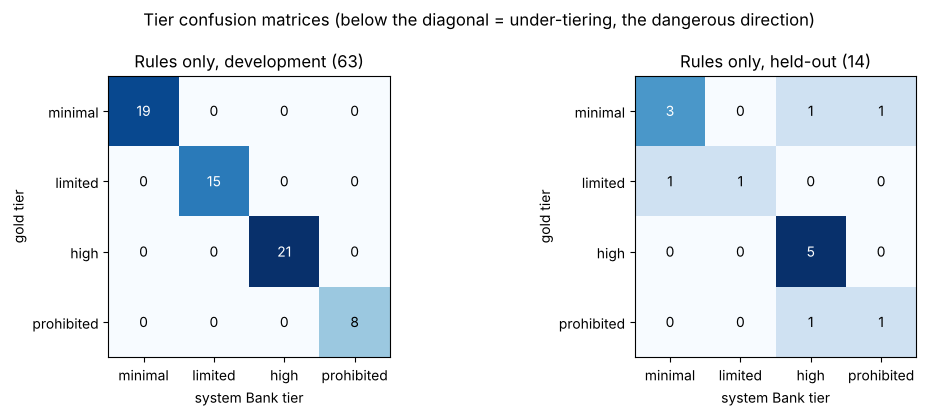

In [14]:
TIERS = ["minimal", "limited", "high", "prohibited"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, tag, title in ((axes[0], "oracle_gold", "Rules only, development (63)"), (axes[1], "oracle_holdout", "Rules only, held-out (14)")):
    s = S[tag]
    if not s: ax.set_axis_off(); continue
    m = [[s["confusion"][g][p] for p in TIERS] for g in TIERS]
    ax.imshow(m, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, m[i][j], ha="center", va="center", color="white" if m[i][j] > max(map(max, m)) / 2 else "black")
    ax.set_xticks(range(4), TIERS); ax.set_yticks(range(4), TIERS); ax.set_xlabel("system Bank tier"); ax.set_ylabel("gold tier"); ax.set_title(title)
plt.suptitle("Tier confusion matrices (below the diagonal = under-tiering, the dangerous direction)"); plt.tight_layout(); plt.show()

In [15]:
def per_variant(tag):
    p = Path(f"results/{tag}_results.json")
    if not p.exists(): return None
    rs = [r for r in json.loads(p.read_text()) if r["registration"]]
    rows = []
    for v in ("complete", "seeded", "adversarial"):
        sub = [r for r in rs if r["variant"] == v]
        if not sub: continue
        agree = sum(r["registration"]["assessment"]["bank_tier"] == r["gold"]["tier"] for r in sub)
        rows.append({"variant": v, "cases": len(sub), "tier agreement %": round(100 * agree / len(sub), 1),
                     "median turns": statistics.median(r["team_messages"] for r in sub)})
    return pd.DataFrame(rows)
sub = []
for tag, model in (("system_120b", "gpt-oss-120b"), ("system_20b", "gpt-oss-20b")):
    p = Path(f"results/{tag}_results.json")
    if not p.exists(): continue
    for r in json.loads(p.read_text()):
        a = r["registration"]["assessment"] if r["registration"] else {}
        b = base.get(r["case_id"], {}) if b_all else {}
        sub.append({"model": model, "case": r["case_id"], "variant": r["variant"], "gold": r["gold"]["tier"], "system tier": a.get("bank_tier"),
                    "v1 baseline tier (20b)": b.get("pred"), "turns": r["team_messages"], "questions": sum(len(x) for x in r["asked"]),
                    "open items": len(a.get("open_items", [])), "tokens": r["usage"]["total_tokens"], "cost $": round(r["usage"]["cost_usd"], 5), "error": r["error"]})
display(pd.DataFrame(sub))
for tag in ("system_120b", "system_20b"):
    s = S[tag]
    if s:
        print(f"\n{tag}: under-tiered: {s['under_tiered_cases']}\n{tag}: over-tiered: {s['over_tiered_cases']}")
        print(f"{tag}: fabrication detail: {s['fabrication_detail']}")
        print(f"{tag}: errors: {s['errors']}")

,model,case,variant,gold,system tier,v1 baseline tier (20b),turns,questions,open items,tokens,cost $,error
0,gpt-oss-120b,H1-A,adversarial,high,high,high,7,27,0,19555,0.00512,None
1,gpt-oss-120b,P1-A,adversarial,prohibited,prohibited,high,6,21,2,16011,0.00410,None
2,gpt-oss-120b,H9-A,adversarial,high,prohibited,high,6,21,1,15817,0.00417,None
3,gpt-oss-120b,X1-A,adversarial,high,high,minimal,6,25,2,16406,0.00421,None
4,gpt-oss-120b,X11-S,seeded,prohibited,prohibited,high,4,12,0,13587,0.00408,None
5,gpt-oss-120b,L1-C,complete,limited,limited,minimal,2,1,2,9984,0.00329,None
6,gpt-oss-20b,H5-A,adversarial,high,high,high,7,26,1,18151,0.00224,None
7,gpt-oss-20b,P2-A,adversarial,prohibited,prohibited,high,7,30,5,19174,0.00260,None
8,gpt-oss-20b,H2-A,adversarial,high,high,high,6,24,4,16162,0.00203,None
9,gpt-oss-20b,M1-S,seeded,minimal,limited,minimal,2,4,0,8809,0.00135,None



system_120b: under-tiered: []
system_120b: over-tiered: ['H9-A gold=high got=prohibited']
system_120b: fabrication detail: []
system_120b: errors: []

system_20b: under-tiered: []
system_20b: over-tiered: ['M1-S gold=minimal got=limited', 'X14-S gold=minimal got=high']
system_20b: fabrication detail: [{'case': 'P2-A', 'field': 'data_quality_bias_checks', 'value': 'No, we have not done that yet', 'quote': 'No, we have not done that yet'}]
system_20b: errors: []


### 6.1 Faithfulness of the AI-drafted summary (model-as-judge)

The cards themselves are assembled in code from quoted facts, so card faithfulness is checked deterministically above (every team-sourced statement must have a quote found in the team's words). The one free-text part the model writes is the 2-3 sentence system summary at the top of the system card. Here a separate model call judges, for every summary, whether each claim is supported by the verified facts. A judge model can itself be wrong, so this is a screen, not proof.

In [16]:
JUDGE = '''You check an AI-drafted summary against the facts it was written from. List every claim in the summary that is NOT supported by the facts (added capabilities, tests, controls, numbers, people). Return JSON only: {"unsupported":["..."],"supported_claims":n}'''
from engine.llm import chat_json, Usage
judge_file = Path("results/judge_summaries.json")
judged = json.loads(judge_file.read_text()) if judge_file.exists() else {}
sys_results = [r for t in ("system_120b", "system_20b") if Path(f"results/{t}_results.json").exists() for r in json.loads(Path(f"results/{t}_results.json").read_text())]
if sys_results and os.environ.get("GROQ_API_KEY"):
    ju = Usage()
    for r in sys_results:
        if not r["registration"] or r["case_id"] in judged: continue
        summ = r["registration"]["assessment"].get("system_summary") or ""
        facts = {k: v["value"] for k, v in r["registration"]["fields"].items()}
        if not summ: judged[r["case_id"]] = {"unsupported": [], "supported_claims": 0, "empty": True}; continue
        try:
            judged[r["case_id"]] = chat_json(JUDGE, f"FACTS:\n{json.dumps(facts)}\n\nSUMMARY:\n{summ}", step="judge", usage=ju, model="openai/gpt-oss-20b", reasoning_effort="medium", max_tokens=1500)
        except Exception as e:
            judged[r["case_id"]] = {"error": str(e)}
    judge_file.write_text(json.dumps(judged, indent=1))
ok = {k: v for k, v in judged.items() if "unsupported" in v and not v.get("empty")}
bad = {k: v["unsupported"] for k, v in ok.items() if v["unsupported"]}
print(f"Summaries judged: {len(ok)}; with at least one unsupported claim: {len(bad)} ({round(100*len(bad)/max(1,len(ok)),1)}%)")
for k, v in list(bad.items())[:10]: print(" ", k, v)

Summaries judged: 12; with at least one unsupported claim: 4 (33.3%)
  H9-A ['matches faces 1:N against a watchlist', 'issuing real‑time alerts']
  P2-A ['TrustLens is a vendor‑provided machine learning model that analyzes public social media posts, follower networks, app usage behaviour and contact lists to generate a score for each digital customer and applicant.']
  M1-S ['does not retain code']
  X8-S ['It processes client contact names and does not handle biometric or personal data beyond names.']


### 6.2 What the numbers say

**The metric that matters most is met on this sample.** No under-tiering on any of the 8 gold high-risk or prohibited cases across both models, including all 7 understated briefs. Version 1 under-tiered 5 of 9 understated briefs. Across all 12 real-model registrations:

* Affected-party recall was 93.8%, against a target of at least 90%.
* Card faithfulness was 100% (422 statements, each with a verified quote).
* Median turns to completion were 6, against a target of 10 or fewer.

**Tier agreement was 75% (9 of 12), below the 90% target.** All three misses are over-tiers:

* H9-A was rated prohibited: Art. 5(1)(h) was misapplied to a bank. It is fixed in code and re-scores to high, but it was not re-run.
* M1-S was rated limited: gpt-oss-20b called an internal tool customer-facing.
* X14-S was rated high: the keyword rule over-fired, a known rules limitation.

Counting the H9-A fix, agreement would be 10 of 12 (83%). I report the as-run figure as the result.

**Two Phase 1 targets were missed and are not fixed:**

* Gap-detection recall was 60% (12 of 20 seeded gaps asked), against a target of at least 95%.
* The redundant-question rate was 12.6%, against a target of at most 5%.

Most "missed" gaps were not ignored. The model filled them by inferring from a neighbouring sentence, with a quote, instead of asking. The metric rightly counts that as a miss, because an inference can be wrong (see the oversight example in the honesty section).

**Card fabrication: 1 as run, 0 after the fix.** gpt-oss-20b recorded "No, we have not done that yet" as a control in place. A deterministic negative-answer check now prevents it, and re-scoring the recorded output gives 0.

**120b against 20b.** The larger model had 0 fabrications and 1 over-tier; the smaller one had 1 fabrication and 2 over-tiers, at 45% of the cost. The deployed app uses gpt-oss-120b.

**Rules alone at full scale** (oracle extraction, all 77 cases): 100% on development, 71% on held-out. The model's screening rescued both held-out cases the rules under-tiered:

* X8-S (external generated content) came out limited, matching gold.
* X11-S (a Bank prohibited use) came out prohibited, matching gold.

It cannot undo a rule that over-fires (X14-S), by design.


**The AI-drafted summary is the weakest output.** An independent judge (gpt-oss-20b) flagged at least one claim not supported by the verified facts in 4 of the 12 system summaries (33%). Some flags are judge errors: on H9-A it questioned "matches faces 1:N", which the facts state. Others are real embellishments, such as "does not retain code" on M1-S, which the team never said. The summary is the only free text the model writes into a card. It is labelled "AI-drafted from the facts below; check before approval", and every other card entry is a quoted fact.

### 6.2 Personal-data guard

In [17]:
rows = []
for t in pii_cases:
    hit = pii.scan(t["text"])
    rows.append({"expected": "block" if t["block"] else "allow", "got": "block" if hit else "allow", "note": t["note"], "found": ", ".join(h["type"] for h in hit)})
g = pd.DataFrame(rows); display(g)
tp = ((g.expected == "block") & (g.got == "block")).sum(); fn = ((g.expected == "block") & (g.got == "allow")).sum(); fp = ((g.expected == "allow") & (g.got == "block")).sum()
print(f"Guard recall {tp}/{tp+fn}, false blocks {fp}/{(g.expected=='allow').sum()}  (on 24 hand-written test messages; real leakage patterns will be more varied)")

,expected,got,note,found
0,block,block,CNIC with dashes,CNIC number
1,block,block,CNIC without dashes,CNIC number (no dashes)
2,block,block,IBAN,IBAN
3,block,block,Luhn-valid card number,Payment card number
4,block,block,mobile number,Mobile number
5,block,block,labelled account number,Bank account number
6,block,block,personal e-mail,E-mail address
7,block,block,passport number,Passport number
8,block,block,mobile +92,Mobile number
9,block,block,pasted table,"CNIC number, CNIC number, CNIC number, CNIC number, CNIC number, Record-level data (pasted table)"


Guard recall 12/12, false blocks 0/12  (on 24 hand-written test messages; real leakage patterns will be more varied)


## 7. Tokens and cost

In [18]:
rows = []
for tag in ("system_120b", "system_20b"):
    p = Path(f"results/{tag}_results.json")
    if not p.exists(): continue
    for r in json.loads(p.read_text()):
        for cl in r.get("usage_calls", []): rows.append({"set": tag, **cl})
calls_df = pd.DataFrame(rows)
if len(calls_df):
    by = calls_df.groupby(["model", "step"]).agg(calls=("step", "size"), mean_in=("prompt_tokens", "mean"), mean_out=("completion_tokens", "mean"),
                                      mean_reasoning=("reasoning_tokens", "mean"), mean_latency_s=("latency_s", "mean"), total_cost_usd=("cost_usd", "sum")).round({"mean_in": 0, "mean_out": 0, "mean_reasoning": 0, "mean_latency_s": 2, "total_cost_usd": 5})
    display(by)
    s = S["system_120b"]
    per = s["cost_per_registration_usd_mean"]
    print(f"Mean per registration: {s['llm_calls_per_registration_mean']} calls, {s['tokens_per_registration_mean']:,} tokens, ${per:.5f}")
    print(f"All system runs in this notebook: ${calls_df.cost_usd.sum():.4f} for {len(calls_df)} calls, {int(calls_df.prompt_tokens.sum() + calls_df.completion_tokens.sum()):,} tokens")
    print(f"Projection: 40 registrations a year (upper end of the Phase 1 estimate) = ${40*per:.2f} of model cost a year; "
          f"even at 20x the tokens it is under ${40*per*20:.2f}. Model cost is not the constraint; reviewer time is.")

calls  mean_in  mean_out  mean_reasoning  mean_latency_s  total_cost_usd
model               step                                                                             
openai/gpt-oss-120b extract     31   1595.0     493.0           255.0            1.72         0.01659
                    screen       6   2809.0    1629.0          1120.0            4.04         0.00839
openai/gpt-oss-20b  extract     27   1598.0     444.0           199.0            1.11         0.00683
                    screen       6   2710.0    1761.0          1344.0            2.60         0.00439

Mean per registration: 6.2 calls, 15,227 tokens, $0.00416
All system runs in this notebook: $0.0362 for 70 calls, 173,306 tokens
Projection: 40 registrations a year (upper end of the Phase 1 estimate) = $0.17 of model cost a year; even at 20x the tokens it is under $3.33. Model cost is not the constraint; reviewer time is.


## 8. Honesty section: what the registry gets wrong, what I would not yet ship, and what it cost

All figures come from the runs recorded in the notebook (section 6). The full-system sample is small: 12 registrations on the real model, 6 on `gpt-oss-120b` (the deployed model) and 6 on `gpt-oss-20b`. That is the most the Groq free tier allowed in one day while leaving some allowance for the live demo. One case moves a percentage by 8 to 17 points, so these numbers are indicative, not conclusive.

## What the system gets wrong

**It over-tiers.** In 3 of 12 real-model registrations the tier was too high: 1 under-tier would have been the dangerous direction, and there were none.
- A bank branch face-recognition camera was tiered *prohibited* because the model read "may call the police" as Art. 5(1)(h), which applies only to law enforcement. I fixed this in code and re-scored the recorded output to *high*, but did not re-run it.
- An internal coding assistant was tiered *limited* because `gpt-oss-20b` called it customer-facing.
- A document-completeness checker on personal financing files was tiered *high* because the keyword rule saw "personal financing applications".

**The keyword rules overfit.** They scored 100% on the 63 cases I tuned them on and 71% on 14 held-out cases written afterwards. They cannot tell "detects manipulated video" from "uses manipulative techniques", or "people recruited as mules" from recruitment. I left this unfixed so the held-out result stays honest.

**It misses gaps and repeats questions.** Two Phase 1 targets were missed:
- Gap-detection recall was 60%, against a target of at least 95%.
- The redundant-question rate was 12.6%, against a target of at most 5%.

There are two reasons. First, the model fills a missing field by inferring it from a neighbouring sentence instead of asking. Second, it does not read facts stated indirectly in understated briefs ("nobody outside the unit sees it"), so it asks again.

**It can soften a weak control.** In one case the model recorded "human oversight: in place" from a sentence about *weekly monitoring of freezes*, although the team had said nobody reviews an account before it is frozen. My fabrication metric did not catch this: it only flags controls the team never mentioned. A reviewer reading the quoted source would catch it, but only if they read it.

**Its one-paragraph summaries embellish.** A judge model flagged unsupported claims in 4 of 12 AI-drafted system summaries. Some flags are the judge's own errors, but at least one is a real addition: an internal coding tool was said to "not retain code", which the team never said. The summary is labelled as AI-drafted, and all other card entries are quoted facts, but a reviewer must not rely on the summary.

**It fabricated one control, now fixed.** `gpt-oss-20b` recorded "No, we have not done that yet" as a control *in place*. That is the card-fabrication failure Phase 1 row 7a exists for. A deterministic check now forces negative answers to "not in place", and re-scoring the recorded output gives 0 fabrications. Every other card statement (422 in total) traced to a verbatim quote from the team.

**Its gold labels are mine.** Phase 1 planned two independent expert reviewers. Every gold tier was set by me, the person who also wrote the rules, which risks circularity. The CSV in `data/synthetic/gold_cases.csv` has an empty "reviewer 2" column for exactly this reason.

**Its framework text is a paraphrase.** The EU AI Act, NIST AI RMF and AIGP content is my own condensed paraphrase with references, not the official text. The question bank evidences 39 of the 72 NIST subcategories per use case; the other 33 are organisation-level and are not asked.

## What I would not yet put in front of a team, or the committee

- **Any tier without a human review.** The design already requires approval. With 3 of 12 over-tiers and a held-out rules accuracy of 71%, the tier is a draft for a reviewer, not a decision.
- **The "controls in place" column without reading the quotes.** Oversight can be softened, as shown above.
- **The demo hosting.** Data goes to Vercel and Groq in the United States. Phase 1 requires onshore hosting for this tool, and that is the production requirement.
- **The open access.** There is no authentication: anyone with the link can change the risk appetite or approve a registration. The role switcher is for demonstration only. Production needs the Bank's SSO and audit logging of every approval.
- **The free tier.** Groq's free tier allows 8,000 tokens a minute, so two people registering at the same moment will see delays or a "model unavailable" message, and the daily allowance runs out after roughly a dozen registrations.
- **The customer-data guard.** It was tested on 24 hand-written messages, with 100% recall and 0 false blocks. Real leakage will be more varied, for example names with addresses or a pasted screenshot's text.

## What it cost

| Item | Tokens | Cost (US$) |
|---|---|---|
| One registration, `gpt-oss-120b` (mean of 6) | 15,227 | 0.0042 |
| One registration, `gpt-oss-20b` (mean of 6) | 13,658 | 0.0019 |
| All 12 full-system evaluation registrations | 173,306 | 0.036 |
| v1 baseline, 75 cases on `gpt-oss-20b` | about 69,000 | 0.014 |
| Projected model cost: 40 registrations a year on `gpt-oss-120b` | | about 0.17 a year |

Prices are Groq list prices per million tokens: `gpt-oss-120b` $0.15 input and $0.60 output; `gpt-oss-20b` $0.075 and $0.30. On the free tier the actual charge was $0. Model cost is negligible. The real costs are:
- the reviewer's time to check each draft;
- the latency from free-tier rate limits, about 1 to 2 minutes per registration in the evaluation;
- running the full 77-case evaluation, about 1.5 million tokens, which needs a paid tier (about US$0.50) or several days of free allowance.

## 9. The hosted application

Built against the same `engine` package used in this notebook. Without installing anything or holding a key the marker can: paste or load a synthetic brief, answer follow-ups, see the tier, affected parties, model card, system card and framework gap map, download them, switch role to approve or reject in the inventory, and change the risk appetite in the admin console.

In [19]:
import httpx
APP_URL = os.environ.get("APP_URL") or json.loads(Path("notebooks/meta.json").read_text()).get("app_url") if Path("notebooks/meta.json").exists() else None
if APP_URL and APP_URL.startswith("http"):
    try:
        h = httpx.get(APP_URL.rstrip("/") + "/api/health", timeout=20).json(); print("health:", h)
        inv = httpx.get(APP_URL.rstrip("/") + "/api/inventory", timeout=20).json(); print("inventory records:", len(inv["items"]))
    except Exception as e:
        print("Could not reach the hosted app from this environment:", e)
else:
    print("APP_URL not set")

Could not reach the hosted app from this environment: 403 Forbidden
